# Лабораторная работа №2. Метод ломаных — Python-версия
Борисюк Е. Г.

**Основная реализация работы — Kotlin/JVM. Эта дополнительная версия для Google Colab подготовлена с помощью ИИ-перевода Kotlin-кода на Python. Формулы, разбор выражения, выбор интервалов и результат проверены сравнением двух реализаций.**

Для демонстрации выбрано сечение двумерной функции Растригина при второй координате, равной нулю:
$$f(x)=x^2+10(1-\cos(2\pi x)),\quad x\in[-2,2],\quad \varepsilon=0.01.$$
На отрезке несколько локальных минимумов. Из $f(x)\ge x^2\ge0$ и $f(0)=0$ известен точный глобальный ответ $x^*=0$, $f^*=0$.

Программа принимает строку функции, границы и точность **по значению функции**. Поддерживаются минимум и максимум. Константа Липшица оценивается аналитически по структуре выражения; при необходимости можно передать известную корректную границу `L` вручную. Если автоматическая оценка не получена, программа сообщает об этом, а не подменяет доказательство сеткой.


### Служебные типы, разбор строки и вычисление выражения

In [1]:
"""Дополнительная версия: ИИ-перевод основной Kotlin/JVM-реализации."""
import heapq
import math
import re
from dataclasses import dataclass
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt


# Узел дерева: число, переменная, операция или вызов функции.
@dataclass
class Expr:
    kind: str
    text: str = ''
    children: tuple = ()


# Разбираем строку с учётом скобок и приоритетов операций.
class ExpressionParser:
    def __init__(self, expression):
        self.source, self.pos = expression, 0

    def skip(self):
        while self.pos < len(self.source) and self.source[self.pos].isspace():
            self.pos += 1

    def take(self, token):
        self.skip()
        if not self.source.startswith(token, self.pos):
            return False
        self.pos += len(token)
        return True

    def parse(self):
        node = self.sum()
        self.skip()
        if self.pos != len(self.source):
            raise ValueError(f'Лишний символ в позиции {self.pos}')
        return node

    # Сначала разбираем произведения, затем сложение и вычитание.
    def sum(self):
        node = self.product()
        while True:
            if self.take('+'):
                node = Expr('binary', '+', (node, self.product()))
            elif self.take('-'):
                node = Expr('binary', '-', (node, self.product()))
            else:
                return node

    def product(self):
        node = self.unary()
        while True:
            self.skip()
            if self.source.startswith('**', self.pos):
                return node
            if self.take('*'):
                node = Expr('binary', '*', (node, self.unary()))
            elif self.take('/'):
                node = Expr('binary', '/', (node, self.unary()))
            else:
                return node

    def unary(self):
        if self.take('+'):
            return Expr('unary', '+', (self.unary(),))
        if self.take('-'):
            return Expr('unary', '-', (self.unary(),))
        return self.power()

    # Степени разбираем справа налево: 2**3**2 = 2**(3**2).
    def power(self):
        node = self.atom()
        return Expr('binary', '**', (node, self.unary())) if self.take('**') else node

    # Читаем число, имя, функцию или выражение в скобках.
    def atom(self):
        self.skip()
        if self.take('('):
            node = self.sum()
            if not self.take(')'):
                raise ValueError('Нет закрывающей скобки')
            return node
        if self.pos >= len(self.source):
            raise ValueError('Неожиданный конец выражения')
        if self.source[self.pos].isdigit() or self.source[self.pos] == '.':
            match = re.match(r'(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?', self.source[self.pos:])
            if match is None or not math.isfinite(float(match[0])):
                raise ValueError('Некорректная числовая константа')
            self.pos += len(match[0])
            return Expr('number', match[0])
        start = self.pos
        while self.pos < len(self.source) and self.source[self.pos].isalpha():
            self.pos += 1
        name = self.source[start:self.pos]
        if name in ('x', 'pi', 'e'):
            return Expr('name', name)
        if name not in ('sin', 'cos', 'exp', 'log', 'sqrt', 'abs') or not self.take('('):
            raise ValueError('Неизвестное имя или вызов: ' + name)
        argument = self.sum()
        if not self.take(')'):
            raise ValueError('Нет закрывающей скобки функции')
        return Expr('call', name, (argument,))


# Вычисляем дерево выражения при заданном x.
def evaluate(node, x):
    args = [evaluate(child, x) for child in node.children]
    if node.kind == 'number':
        return float(node.text)
    if node.kind == 'name':
        return {'x': x, 'pi': math.pi, 'e': math.e}[node.text]
    if node.kind == 'unary':
        return -args[0] if node.text == '-' else args[0]
    if node.kind == 'call':
        functions = {name: getattr(math, name) for name in ('sin','cos','exp','log','sqrt')}
        functions['abs'] = abs
        return functions[node.text](args[0])
    u, v = args
    if node.text == '+': return u + v
    if node.text == '-': return u - v
    if node.text == '*': return u * v
    if node.text == '/': return u / v
    return math.pow(u, v)


### Чтение строки функции

In [2]:
def make_function(expression):
    # Собственный разбор строки, как в Kotlin; произвольный код не выполняется.
    tree = ExpressionParser(expression).parse()
    return lambda x: evaluate(tree, x), tree


### Оценка константы Липшица

In [3]:
def lipschitz_bound(node, a, b):
    # Диапазон и аналитическая оценка L для каждого узла выражения.
    def bound(t):
        if t.kind == 'number': return float(t.text), float(t.text), 0.0
        if t.kind == 'name':
            if t.text == 'x': return a, b, 1.0
            v = {'pi': math.pi, 'e': math.e}[t.text]
            return v, v, 0.0
        lo, hi, Lu = bound(t.children[0])
        if t.kind == 'unary':
            return (-hi, -lo, Lu) if t.text == '-' else (lo, hi, Lu)
        if t.kind == 'call':
            if t.text in ('sin','cos'): return -1.0, 1.0, Lu
            if t.text == 'exp': return math.exp(lo), math.exp(hi), math.exp(hi)*Lu
            if t.text == 'log' and lo > 0: return math.log(lo), math.log(hi), Lu/lo
            if t.text == 'sqrt' and lo > 0: return math.sqrt(lo), math.sqrt(hi), Lu/(2*math.sqrt(lo))
            if t.text == 'abs':
                return (0.0 if lo <= 0 <= hi else min(abs(lo),abs(hi)), max(abs(lo),abs(hi)), Lu)
            raise ValueError('Для этого выражения задайте корректное L вручную')
        low, high, Lv = bound(t.children[1])
        M, N = max(abs(lo),abs(hi)), max(abs(low),abs(high))
        if t.text == '+': return lo+low, hi+high, Lu+Lv
        if t.text == '-': return lo-high, hi-low, Lu+Lv
        if t.text == '*':
            values = [lo*low,lo*high,hi*low,hi*high]
            # Для произведения: L(uv) <= max|v|*L(u) + max|u|*L(v).
            return min(values),max(values),N*Lu+M*Lv
        if t.text == '/' and not low <= 0 <= high:
            values = [lo/low,lo/high,hi/low,hi/high]
            d = min(abs(low),abs(high))
            return min(values),max(values),Lu/d+M*Lv/d**2
        if t.text == '**' and Lv == 0 and low == high and low.is_integer():
            n = int(low)
            if n == 0: return 1.0,1.0,0.0
            if n > 0:
                values = [lo**n,hi**n] + ([0.0] if lo <= 0 <= hi else [])
                return min(values),max(values),n*M**(n-1)*Lu
            if not lo <= 0 <= hi:
                values = [lo**n,hi**n]
                return min(values),max(values),abs(n)*min(abs(lo),abs(hi))**(n-1)*Lu
        raise ValueError('Не удалось оценить L автоматически; задайте его вручную')
    L = bound(node)[2]
    if not math.isfinite(L): raise ValueError('Оценка L должна быть конечной')
    return max(L*(1+1e-12),1e-12)


### Пересечение прямых

In [4]:
def intersection(xl, fl, xr, fr, L):
    # Пересечение двух опорных прямых внутри соседнего интервала.
    x = (xl + xr) / 2 - (fr - fl) / (2 * L)
    lower = (fl + fr - L * (xr - xl)) / 2
    return x, lower


### Метод ломаных

In [5]:
def piyavskii(expression, a, b, eps=0.01, L=None, direction='min', max_iter=100000):
    # Проверяем отрезок, точность и направление поиска.
    if not (math.isfinite(a) and math.isfinite(b) and a < b):
        raise ValueError('Нужен конечный отрезок a < b')
    if not math.isfinite(eps) or eps <= 0 or max_iter <= 0:
        raise ValueError('eps и max_iter должны быть положительными')
    if direction not in ('min', 'max'):
        raise ValueError('direction должен быть min или max')
    f, tree = make_function(expression)
    # Берём заданное L или оцениваем его по дереву выражения.
    L = lipschitz_bound(tree, a, b) if L is None else float(L)
    if not math.isfinite(L) or L <= 0:
        raise ValueError('L должно быть положительным и конечным')
    # Максимум ищем через минимум функции -f.
    sign = 1 if direction == 'min' else -1

    def value(x):
        y = sign * float(f(x))
        if not math.isfinite(y):
            raise ValueError('Функция должна быть конечной на отрезке')
        return y

    # Засекаем время самого метода, без разбора строки и графика.
    started = perf_counter()
    # Две начальные пробы на концах отрезка.
    fa, fb = value(a), value(b)
    samples = {a: fa, b: fb}
    # Лучшая проба даёт верхнюю оценку минимума.
    x_best, upper = min(samples.items(), key=lambda p: p[1])
    heap, history = [], []

    def add_interval(xl, fl, xr, fr):
        # Проверяем согласованность L с уже известными пробами.
        if abs(fr - fl) > L * (xr - xl) + 1e-10 * max(1, abs(fl), abs(fr)):
            raise ValueError('Заданное L противоречит уже вычисленным значениям')
        x, lower = intersection(xl, fl, xr, fr, L)
        # Куча выдаёт первым интервал с наименьшим lower.
        heapq.heappush(heap, (lower, xl, xr, fl, fr, x))

    add_interval(a, fa, b, fb)
    iteration = 0
    while True:
        # 1. Читаем самую низкую оценку из очереди интервалов.
        lower = heap[0][0]
        history.append({'iteration': iteration, 'upper': upper,
                        'lower': lower, 'gap': upper - lower, 'x_best': x_best,
                        'candidate': heap[0][5], 'left': heap[0][1], 'right': heap[0][2]})
        # 2. Останавливаемся, когда разрыв оценок не больше eps.
        if upper - lower <= eps:
            break
        if iteration >= max_iter:
            raise RuntimeError('Превышен max_iter, точность ещё не достигнута')
        # 3. Удаляем выбранный интервал и берём его нижнюю вершину.
        _, xl, xr, fl, fr, x = heapq.heappop(heap)
        if not xl < x < xr or x in samples:
            raise RuntimeError('Достигнут предел машинной точности')
        # Вычисляем и сохраняем новую пробу функции.
        fx = value(x)
        samples[x] = fx
        # 4. При необходимости обновляем лучший найденный ответ.
        if fx < upper:
            x_best, upper = x, fx
        # 5. Вместо выбранного интервала добавляем два новых.
        add_interval(xl, fl, x, fx)
        add_interval(x, fx, xr, fr)
        iteration += 1

    elapsed = perf_counter() - started
    vertices = sorted(samples.items())
    # Возвращаем ответ и границы в знаках исходной функции.
    return {'expression': expression, 'a': a, 'b': b, 'eps': eps, 'L': L,
            'direction': direction, 'x': x_best, 'fun': sign * upper,
            'lower': lower if sign == 1 else -upper,
            'upper': upper if sign == 1 else -lower,
            'gap': upper - lower, 'iterations': iteration,
            'evaluations': len(samples), 'seconds': elapsed,
            'samples': [(x, sign*y) for x, y in vertices], 'history': history}


### Построение графика

In [6]:
def plot_result(result, path=None):
    f, _ = make_function(result['expression'])
    sign = 1 if result['direction'] == 'min' else -1
    points = [(x, sign*y) for x, y in result['samples']]
    # Точные вершины ломаной; сетка используется только для рисунка f(x).
    vx, vy = [points[0][0]], [points[0][1]]
    for (xl, fl), (xr, fr) in zip(points, points[1:]):
        x, y = intersection(xl, fl, xr, fr, result['L'])
        vx.extend([x, xr]); vy.extend([y, fr])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    grid = np.linspace(result['a'], result['b'], 2500)
    values = np.array([float(f(x)) for x in grid])
    for ax in axes:
        ax.plot(grid, values, color='#1d4f91', label='Исходная функция')
        ax.plot(vx, sign*np.array(vy), color='#d47a14', lw=0.9, label='Итоговая ломаная')
        ax.scatter(*zip(*result['samples']), s=7, color='#728195', alpha=0.35)
        ax.scatter([result['x']], [result['fun']], color='#bb2233', zorder=5, label='Найденный экстремум')
        ax.set_xlabel('x'); ax.set_ylabel('f(x)'); ax.grid(alpha=0.2)
    axes[0].set_title('Весь отрезок'); axes[0].legend(fontsize=8)
    # Во второй части рисунка увеличиваем окрестность найденной точки.
    width = min((result['b']-result['a'])/4, 0.15)
    axes[1].set_xlim(max(result['a'],result['x']-width), min(result['b'],result['x']+width))
    level = result['fun']
    axes[1].set_ylim(level-max(0.03,3*result['eps']), level+max(0.1,10*result['eps']))
    axes[1].set_title('Увеличение около найденной точки')
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig


### Демонстрация и результат
Сначала вычисляются точки метода и границы минимума. Сетка создаётся только внутри функции рисования и не участвует в поиске.

Функция: x**2 + 10*(1-cos(2*pi*x))
Отрезок: (-2.0, 2.0) eps = 0.01
L = 66.8318530719
x_min = 0.0000000000; f_min = 0.0000000000
Границы минимума: [-0.0086279513, 0.0000000000]
Разрыв = 0.0086279513 <= 0.01
Итераций: 131 Вычислений функции: 133
Время расчёта: 0.000517 с (без графика)


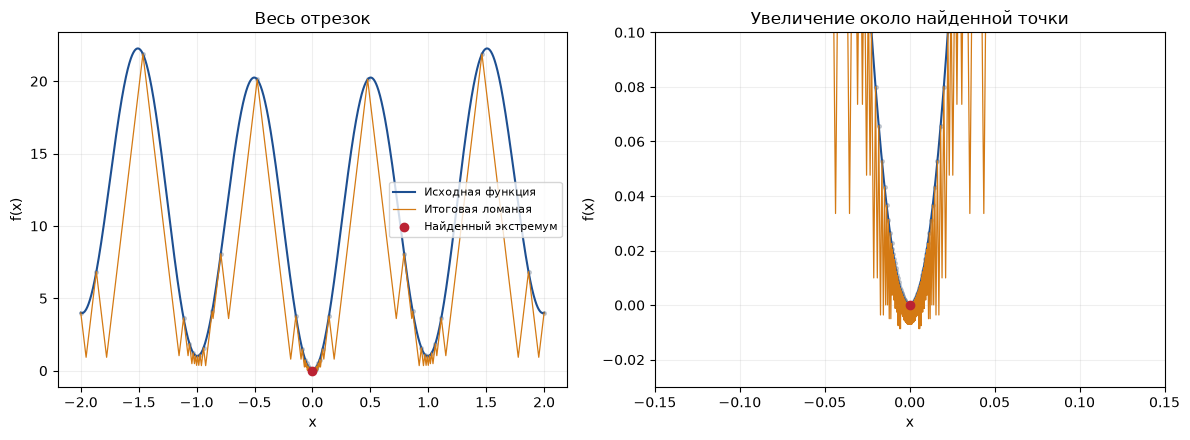

In [7]:
# Входные данные: менять можно только этот блок.
expression = 'x**2 + 10*(1-cos(2*pi*x))'
a, b, eps = -2.0, 2.0, 0.01
result = piyavskii(expression, a, b, eps)

print('Функция:', expression)
print('Отрезок:', (a, b), 'eps =', eps)
print(f"L = {result['L']:.10f}")
print(f"x_min = {result['x']:.10f}; f_min = {result['fun']:.10f}")
print(f"Границы минимума: [{result['lower']:.10f}, {result['upper']:.10f}]")
print(f"Разрыв = {result['gap']:.10f} <= {eps}")
print('Итераций:', result['iterations'], 'Вычислений функции:', result['evaluations'])
print(f"Время расчёта: {result['seconds']:.6f} с (без графика)")
assert result['gap'] <= eps
assert result['lower'] <= 0 <= result['upper']

fig = plot_result(result, 'visualization.png')
plt.show()


### Проверка результата
Найдено $x=0$, $f(x)=0$. Аналитически $f(x)=x^2+10(1-\cos(2\pi x))\ge0$, поэтому точка глобально оптимальна.

Даже после попадания в точный минимум алгоритм продолжает работу, пока нижняя оценка на **всём отрезке** не станет ближе к лучшему значению, чем `eps`.

`iterations` — число новых проб после двух концов отрезка; `evaluations = iterations + 2`. Время зависит от среды выполнения. Погрешность `eps` относится к значению функции; отдельной гарантии расстояния по x для произвольной функции нет.
